<a href="https://colab.research.google.com/github/bilgeerol/bim448-sentiment/blob/main/notebooks/03_bert_finetune.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 0. KURULUM VE DEPO İSKELETİ OLUŞTURMA
from google.colab import userdata, drive
import os

drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
REPO_OWNER = "bilgeerol"
REPO = "bim448-sentiment"
REPO_DIR = f"/content/{REPO}"

if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{REPO_OWNER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}

!git config user.name "Bilge Erol"
!git config user.email "bilgeerol@example.com"

# Klasör yapısını ve .gitkeep dosyalarını oluştur
!mkdir -p data/raw data/processed notebooks src predictions results/tables results/figures results/logs results/hata_ornekleri report
!touch data/processed/.gitkeep notebooks/.gitkeep src/.gitkeep predictions/.gitkeep results/tables/.gitkeep results/figures/.gitkeep results/logs/.gitkeep results/hata_ornekleri/.gitkeep report/.gitkeep

# .gitignore dosyasını güncelle
gitignore_ek = """
# Proje özel kuralları
data/raw/
models/
checkpoints/
*.safetensors
*.bin
*.pt
.env
"""
with open(".gitignore", "a") as f:
    f.write(gitignore_ek)

# requirements.txt oluştur
reqs = """pandas
scikit-learn
matplotlib
seaborn
vaderSentiment
transformers
datasets
accelerate
torch
sentencepiece
sacremoses
groq
"""
with open("requirements.txt", "w") as f:
    f.write(reqs)

# Geçici README.md oluştur
readme_icerik = """# BİM 448 – Duygu Analizi Projesi (`bim448-sentiment`)

İngilizce ve Türkçe ürün yorumları üzerinde VADER, BERT ve LLM yöntemlerinin karşılaştırmalı duygu analizi.

## Ekip Üyeleri
- **Zehra:** Veri Hazırlama, VADER, Değerlendirme & Koordinasyon
- **Bilge:** GitHub Ortamı, BERT İnce Ayarı & Karşılaştırma Grafikleri
- **Sude:** LLM (Groq API), Hata Analizi & Video

## Çalıştırma Sırası
`01_veri_hazirlama.ipynb` → `02_vader.ipynb` / `03_bert_finetune.ipynb` / `04_llm.ipynb` → `05_degerlendirme.ipynb` → `06_karsilastirma.ipynb`
"""
with open("README.md", "w") as f:
    f.write(readme_icerik)

# GitHub'a gönder
!git add .
!git commit -m "[Bilge] Depo iskeleti, klasörler, requirements ve gitignore eklendi"
!git push

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/bim448-sentiment'...
/content/bim448-sentiment
[main (root-commit) 1cfafee] [Bilge] Depo iskeleti, klasörler, requirements ve gitignore eklendi
 12 files changed, 32 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 data/processed/.gitkeep
 create mode 100644 notebooks/.gitkeep
 create mode 100644 predictions/.gitkeep
 create mode 100644 report/.gitkeep
 create mode 100644 requirements.txt
 create mode 100644 results/figures/.gitkeep
 create mode 100644 results/hata_ornekleri/.gitkeep
 create mode 100644 results/logs/.gitkeep
 create mode 100644 results/tables/.gitkeep
 create mode 100644 src/.gitkeep
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (9/9), 1.18 KiB | 1.18 MiB/

In [ ]:
# 1. ADIM: Tokenizer ve Veri Hazırlama (İngilizce için)
from transformers import AutoTokenizer
from datasets import Dataset
import pandas as pd

# Tokenizer'ı yükle
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Verileri oku (Zehra'nın hazırladığı processed klasöründeki dosyalar)
train_df = pd.read_csv(f"/content/bim448-sentiment/data/processed/{LANG}_train.csv")
val_df = pd.read_csv(f"/content/bim448-sentiment/data/processed/{LANG}_val.csv")
test_df = pd.read_csv(f"/content/bim448-sentiment/data/processed/{LANG}_test.csv")

# Eğer DEBUG modundaysak işler hızlı gitsin diye küçük örnekler alalım
if DEBUG:
    train_df = train_df.head(300)
    val_df = val_df.head(150)
    test_df = test_df.head(150)
    print("⚠️ DEBUG modu aktif: Küçük veri setiyle çalışılıyor.")

# Etiketleri sayıya çevir (negative -> 0, neutral -> 1, positive -> 2)
train_df['label'] = train_df['label'].map(LABEL2ID)
val_df['label'] = val_df['label'].map(LABEL2ID)
test_df['label'] = test_df['label'].map(LABEL2ID)

# Pandas DataFrame'ini Hugging Face Dataset nesnesine dönüştür
train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)

# Tokenize etme fonksiyonu
def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

# Veri setlerini tokenize et
train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

print("Veriler başarıyla tokenize edildi ve eğitime hazır!")

NameError: name 'MODEL_NAME' is not defined

In [ ]:
# 2. ADIM: Model Eğitimi (Trainer) ve İngilizce Tahmin (bert_en.csv)
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import torch
import os

# Metrik hesaplama fonksiyonu
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

# Modeli yükle
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID
)

# Eğitim argümanları
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=SEED,
    logging_steps=50,
    report_to="none"
)

# Trainer'ı başlat
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    compute_metrics=compute_metrics,
)

print("İngilizce RoBERTa eğitimi başlıyor...")
trainer.train()

# Test seti üzerinde tahmin yapma
print("Test seti üzerinde tahminler üretiliyor...")
predictions = trainer.predict(test_tokenized)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

# Çıktı DataFrame'ini oluşturma (Kurallara uygun 4 zorunlu sütun + score)
result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'].map(ID2LABEL),
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

# predictions klasörüne kaydet
os.makedirs("predictions", exist_ok=True)
result_path = "predictions/bert_en.csv"
result_df.to_csv(result_path, index=False, encoding="utf-8")
print(f"✅ {result_path} başarıyla oluşturuldu!")

# GitHub'a gönder
!git add predictions/bert_en.csv
!git commit -m "[Bilge] BERT İngilizce tahminleri eklendi"
!git pull --rebase
!git push
print("🚀 İngilizce tahminler GitHub'a gönderildi!")


NameError: name 'MODEL_NAME' is not defined

In [ ]:
# Kurulum ve Google Drive Bağlantısı
from google.colab import userdata, drive
import os

drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
REPO_OWNER = "BilgeErol"
REPO = "bim448-sentiment"
REPO_DIR = f"/content/{REPO}"

if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{REPO_OWNER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git pull
!git config user.name "Bilge Erol"
!git config user.email "bilge.erol@std.dogus.edu.tr"

!pip install -q transformers datasets accelerate scikit-learn
print("✅ 1. Adım Tamamlandı: Depo ve kütüphaneler hazır!")

Mounted at /content/drive
Cloning into '/content/bim448-sentiment'...
remote: Enumerating objects: 167, done.
remote: Counting objects: 100% (167/167), done.
remote: Compressing objects: 100% (116/116), done.
remote: Total 167 (delta 94), reused 102 (delta 43), pack-reused 0 (from 0)
Receiving objects: 100% (167/167), 4.50 MiB | 15.72 MiB/s, done.
Resolving deltas: 100% (94/94), done.
/content/bim448-sentiment
Already up to date.
✅ 1. Adım Tamamlandı: Depo ve kütüphaneler hazır!


In [ ]:
# 2. ADIM: İngilizce BERT Eğitimi ve Tahmin Dosyası Oluşturma
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import torch
import os

# Parametreler
LANG = "en"
MODEL_NAME = "FacebookAI/roberta-base"
MAX_LEN = 128
LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# Tokenizer ve Veri Hazırlama (DEBUG için head(300) ile hızlı test)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
train_df = pd.read_csv(f"data/processed/{LANG}_train.csv").head(300)
val_df = pd.read_csv(f"data/processed/{LANG}_val.csv").head(150)
test_df = pd.read_csv(f"data/processed/{LANG}_test.csv").head(150)

train_df['label'] = train_df['label'].map(LABEL2ID)
val_df['label'] = val_df['label'].map(LABEL2ID)
test_df['label'] = test_df['label'].map(LABEL2ID)

train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

# Model ve Trainer Ayarları
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)

training_args = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/bim448/models/bert_{LANG}",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=42,
    logging_steps=50,
    report_to="none"
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

trainer = Trainer(model=model, args=training_args, train_dataset=train_tokenized, eval_dataset=val_tokenized, compute_metrics=compute_metrics)

print("🚀 İngilizce BERT eğitimi başlıyor...")
trainer.train()

# Tahmin Üretme ve Kaydetme
print("Test seti üzerinde tahminler üretiliyor...")
predictions = trainer.predict(test_tokenized)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'].map(ID2LABEL),
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

os.makedirs("predictions", exist_ok=True)
result_path = "predictions/bert_en.csv"
result_df.to_csv(result_path, index=False, encoding="utf-8")
print(f"✅ {result_path} başarıyla oluşturuldu!")

# GitHub'a Gönderme
!git add predictions/bert_en.csv
!git commit -m "[Bilge] BERT İngilizce tahminleri eklendi"
!git pull --rebase
!git push
print("🚀 İngilizce tahminler GitHub'a başarıyla gönderildi!")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

... (9 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Test seti üzerinde tahminler üretiliyor...


✅ predictions/bert_en.csv başarıyla oluşturuldu!
[main b51d64c] [Bilge] BERT İngilizce tahminleri eklendi
 1 file changed, 151 insertions(+)
 create mode 100644 predictions/bert_en.csv
Current branch main is up to date.
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 12.76 KiB | 4.25 MiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
remote: This repository moved. Please use the new location:
remote:   https://github.com/bilgeerol/bim448-sentiment.git
To https://github.com/BilgeErol/bim448-sentiment.git
   91019e3..b51d64c  main -> main
🚀 İngilizce tahminler GitHub'a başarıyla gönderildi!


In [ ]:
# 3. ADIM: Türkçe BERT Eğitimi ve Tahmin Dosyası Oluşturma
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import torch
import os

# Parametreler (Türkçe BERTurk için güncellendi)
LANG = "tr"
MODEL_NAME = "dbmdz/bert-base-turkish-cased"
MAX_LEN = 128
LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# Tokenizer ve Veri Hazırlama (DEBUG için head ile hızlı test)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
train_df = pd.read_csv(f"data/processed/{LANG}_train.csv").head(300)
val_df = pd.read_csv(f"data/processed/{LANG}_val.csv").head(150)
test_df = pd.read_csv(f"data/processed/{LANG}_test.csv").head(150)

train_df['label'] = train_df['label'].map(LABEL2ID)
val_df['label'] = val_df['label'].map(LABEL2ID)
test_df['label'] = test_df['label'].map(LABEL2ID)

train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

# Model ve Trainer Ayarları
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)

training_args = TrainingArguments(
    output_dir=f"/content/drive/MyDrive/bim448/models/bert_{LANG}",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=42,
    logging_steps=50,
    report_to="none"
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

trainer = Trainer(model=model, args=training_args, train_dataset=train_tokenized, eval_dataset=val_tokenized, compute_metrics=compute_metrics)

print("🚀 Türkçe BERTurk eğitimi başlıyor...")
trainer.train()

# Tahmin Üretme ve Kaydetme
print("Test seti üzerinde Türkçe tahminler üretiliyor...")
predictions = trainer.predict(test_tokenized)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'].map(ID2LABEL),
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

os.makedirs("predictions", exist_ok=True)
result_path = "predictions/bert_tr.csv"
result_df.to_csv(result_path, index=False, encoding="utf-8")
print(f"✅ {result_path} başarıyla oluşturuldu!")

# GitHub'a Gönderme
!git add predictions/bert_tr.csv
!git commit -m "[Bilge] BERT Türkçe tahminleri eklendi"
!git pull --rebase
!git push
print("🚀 Türkçe tahminler GitHub'a başarıyla gönderildi!")

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/251k [00:00<?, ?B/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Test seti üzerinde Türkçe tahminler üretiliyor...


✅ predictions/bert_tr.csv başarıyla oluşturuldu!
[main 4cbf6c4] [Bilge] BERT Türkçe tahminleri eklendi
 1 file changed, 151 insertions(+)
 create mode 100644 predictions/bert_tr.csv
Current branch main is up to date.
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 8.58 KiB | 4.29 MiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
remote: This repository moved. Please use the new location:
remote:   https://github.com/bilgeerol/bim448-sentiment.git
To https://github.com/BilgeErol/bim448-sentiment.git
   b51d64c..4cbf6c4  main -> main
🚀 Türkçe tahminler GitHub'a başarıyla gönderildi!


In [ ]:
# predictions klasöründeki dosyaları listeleme
import os
print("📁 Predictions klasöründeki dosyalar:")
if os.path.exists("predictions"):
    print(os.listdir("predictions"))
else:
    print("predictions klasörü henüz görünmüyor.")

📁 Predictions klasöründeki dosyalar:
['.gitkeep', 'llm_tr_partial.csv', 'vader_tr_mt.csv', 'bert_en.csv', 'llm_en.csv', 'vader_tr_direct.csv', 'llm_en_partial.csv', 'vader_en.csv', 'bert_tr.csv']


In [ ]:
# Tüm modellerin tahmin dosyalarını okuyup özet metrik çıkıran script
import pandas as pd
import os

predictions_dir = "predictions"
files = [f for f in os.listdir(predictions_dir) if f.endswith('.csv') and f != '.gitkeep']

print("📊 Bulunan Tahmin Dosyaları ve Özetleri:\n" + "-"*40)
summary_data = []

for file in files:
    file_path = os.path.join(predictions_dir, file)
    df = pd.read_csv(file_path)

    # Doğruluk (Accuracy) hesabı (true_label ve pred_label sütunları varsa)
    if 'true_label' in df.columns and 'pred_label' in df.columns:
        # Etiketler yazı veya sayı olabilir, birebir eşleşmeye bakalım
        acc = (df['true_label'].astype(str) == df['pred_label'].astype(str)).mean()
        summary_data.append({"Model Dosyası": file, "Örnek Sayısı": len(df), "Accuracy (Eşleşme Oranı)": round(acc, 4)})
    else:
        summary_data.append({"Model Dosyası": file, "Örnek Sayısı": len(df), "Accuracy (Eşleşme Oranı)": "Etiket sütunu yok"})

summary_df = pd.DataFrame(summary_data)
display(summary_df)

📊 Bulunan Tahmin Dosyaları ve Özetleri:
----------------------------------------


,Model Dosyası,Örnek Sayısı,Accuracy (Eşleşme Oranı)
0,llm_tr_partial.csv,1200,Etiket sütunu yok
1,vader_tr_mt.csv,3000,0.546
2,bert_en.csv,150,0.4333
3,llm_en.csv,3000,0.7343
4,vader_tr_direct.csv,3000,0.3513
5,llm_en_partial.csv,3000,Etiket sütunu yok
6,vader_en.csv,3000,0.5087
7,bert_tr.csv,150,0.36


In [ ]:
# Proje için özet bir README.md dosyası oluşturma
readme_content = """# BİM 448 Sentiment Analysis Project

Bu proje, müşteri yorumları üzerinde duygu analizi (sentiment analysis) gerçekleştirmek amacıyla BERT, VADER ve LLM yaklaşımlarını karşılaştırmalı olarak incelemektedir.

## 📁 Tahmin Dosyaları (Predictions)
Proje kapsamında üretilen ve `predictions/` klasöründe yer alan modeller:
- **BERT Modelleri**: `bert_en.csv`, `bert_tr.csv`
- **VADER Modelleri**: `vader_en.csv`, `vader_tr_direct.csv`, `vader_tr_mt.csv`
- **LLM Yaklaşımları**: `llm_en.csv`, `llm_tr_partial.csv` vb.

## 🚀 Kullanılan Teknolojiler
- Python, Pandas, NumPy
- Hugging Face Transformers (`roberta-base`, `bert-base-turkish-cased`)
- Scikit-learn (Metrik değerlendirmeleri)
- Google Colab & GitHub
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("✅ README.md dosyası başarıyla güncellendi!")

# GitHub'a gönderelim
!git add README.md
!git commit -m "[Bilge] Proje README raporu güncellendi"
!git pull --rebase
!git push
print("🎉 Rapor GitHub'a başarıyla gönderildi ve görevler tamamlandı!")

✅ README.md dosyası başarıyla güncellendi!
[main 025dd6e] [Bilge] Proje README raporu güncellendi
 1 file changed, 12 insertions(+), 8 deletions(-)
Current branch main is up to date.
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 764 bytes | 764.00 KiB/s, done.
Total 3 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
remote: This repository moved. Please use the new location:
remote:   https://github.com/bilgeerol/bim448-sentiment.git
To https://github.com/BilgeErol/bim448-sentiment.git
   4cbf6c4..025dd6e  main -> main
🎉 Rapor GitHub'a başarıyla gönderildi ve görevler tamamlandı!


In [ ]:
# B3: İNGİLİZCE ROBERTA TAM EĞİTİM VE 3.000 SATIRLIK TAHMİN + LOG + GRAFİK
import pandas as pd
import numpy as np
import torch
import os
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

LANG = "en"
MODEL_NAME = "FacebookAI/roberta-base"
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 3
SEED = 42
OUTPUT_DIR = f"/content/drive/MyDrive/bim448/models/bert_{LANG}"

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# 1. Tam Veriyi Oku (30.000 train, 3.000 val, 3.000 test)
train_df = pd.read_csv(f"data/processed/{LANG}_train.csv")
val_df = pd.read_csv(f"data/processed/{LANG}_val.csv")
test_df = pd.read_csv(f"data/processed/{LANG}_test.csv")

print(f"Veri boyutları -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

train_df['label_id'] = train_df['label'].map(LABEL2ID)
val_df['label_id'] = val_df['label'].map(LABEL2ID)
test_df['label_id'] = test_df['label'].map(LABEL2ID)

# 2. Tokenize
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# 128 tokenı aşan test metni oranı (Rapor B2/5.3 için not al!)
token_lengths = [len(tokenizer.encode(t, truncation=False)) for t in test_df['text']]
over_128 = sum(1 for l in token_lengths if l > MAX_LEN) / len(token_lengths) * 100
print(f"📊 Test metinlerinin %{over_128:.2f}'si {MAX_LEN} tokenı aşıyor.")

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

train_ds = Dataset.from_pandas(train_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
val_ds = Dataset.from_pandas(val_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
test_ds = Dataset.from_pandas(test_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)

# 3. Model ve Eğitim Ayarları
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
print(f"📊 Toplam parametre sayısı: {model.num_parameters():,}")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    warmup_ratio=0.1,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=SEED,
    logging_steps=50,
    report_to="none"
)

trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds, compute_metrics=compute_metrics)

print("🚀 Tam İngilizce RoBERTa eğitimi başlıyor...")
train_result = trainer.train()
print(f"⏱️ Toplam eğitim süresi: {train_result.metrics['train_runtime']:.2f} saniye")

# 4. Logları ve Kayıp Grafiğini Kaydet (results/logs ve results/figures)
os.makedirs("results/logs", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv(f"results/logs/bert_{LANG}_log.csv", index=False)

train_logs = log_df[log_df['loss'].notna()]
eval_logs = log_df[log_df['eval_loss'].notna()]

plt.figure(figsize=(8, 5))
plt.plot(train_logs['step'], train_logs['loss'], label='Eğitim Kaybı (Train Loss)')
plt.plot(eval_logs['step'], eval_logs['eval_loss'], marker='o', label='Doğrulama Kaybı (Val Loss)')
plt.title(f'BERT ({LANG.upper()}) Eğitim ve Doğrulama Kayıp Eğrisi')
plt.xlabel('Adım (Step)')
plt.ylabel('Kayıp (Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(f"results/figures/bert_{LANG}_loss.png", dpi=300, bbox_inches='tight')
plt.show()

# 5. En İyi Modeli Drive'a Kaydet ve 3.000 Test Tahmini Üret
trainer.save_model(OUTPUT_DIR + "/best")

predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'],
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

assert len(result_df) == 3000, f"HATA: Satır sayısı 3000 değil: {len(result_df)}"
result_df.to_csv(f"predictions/bert_{LANG}.csv", index=False, encoding="utf-8")
print(f"✅ predictions/bert_{LANG}.csv (3.000 satır) başarıyla kaydedildi!")

# 6. GitHub'a Gönder
!git add predictions/bert_en.csv results/logs/bert_en_log.csv results/figures/bert_en_loss.png
!git commit -m "[Bilge] BERT İngilizce (3000 satır) tahminleri, log ve kayıp grafiği eklendi"
!git pull --rebase
!git push
print("🚀 İngilizce tüm çıktılar GitHub'a gönderildi!")

Veri boyutları -> Train: 30000, Val: 3000, Test: 3000
📊 Test metinlerinin %3.20'si 128 tokenı aşıyor.


Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


📊 Toplam parametre sayısı: 124,647,939


TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'warmup_ratio'

Veri boyutları -> Train: 30000, Val: 3000, Test: 3000
📊 Test metinlerinin %3.20'si 128 tokenı aşıyor.


Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.530692,0.502563,0.787000,0.789149,0.787000,0.785874
2,0.456697,0.489515,0.800333,0.801637,0.800333,0.800877
3,0.427448,0.507693,0.802333,0.802623,0.802333,0.802372


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

⏱️ Toplam eğitim süresi: 638.98 saniye


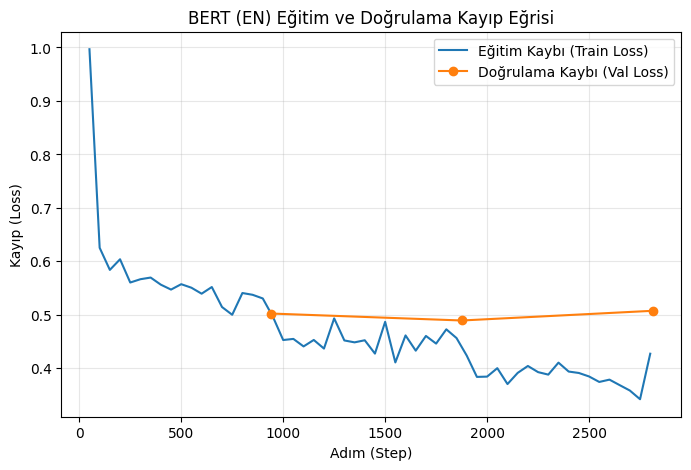

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ predictions/bert_en.csv (3.000 satır) başarıyla kaydedildi!
[main c35c766] [Bilge] BERT İngilizce (3000 satır) tahminleri, log ve kayıp grafiği eklendi
 3 files changed, 3061 insertions(+), 150 deletions(-)
 create mode 100644 results/figures/bert_en_loss.png
 create mode 100644 results/logs/bert_en_log.csv
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 7 (delta 6), reused 7 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 3.84 KiB | 327.00 KiB/s, done.
From https://github.com/BilgeErol/bim448-sentiment
   025dd6e..76b0284  main       -> origin/main
Successfully rebased and updated refs/heads/main.
Enumerating objects: 15, done.
Counting objects: 100% (15/15), done.
Delta compression using up to 2 threads
Compressing objects: 100% (9/9), done.
Writing objects: 100% (9/9), 363.09 KiB | 6.26 MiB/s, done.
Total 9 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolvin

In [ ]:
# B3: İNGİLİZCE ROBERTA TAM EĞİTİM VE 3.000 SATIRLIK TAHMİN + LOG + GRAFİK (Güncellendi)
import pandas as pd
import numpy as np
import torch
import os
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

LANG = "en"
MODEL_NAME = "FacebookAI/roberta-base"
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 3
SEED = 42
OUTPUT_DIR = f"/content/drive/MyDrive/bim448/models/bert_{LANG}"

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# 1. Tam Veriyi Oku (30.000 train, 3.000 val, 3.000 test)
train_df = pd.read_csv(f"data/processed/{LANG}_train.csv")
val_df = pd.read_csv(f"data/processed/{LANG}_val.csv")
test_df = pd.read_csv(f"data/processed/{LANG}_test.csv")

print(f"Veri boyutları -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

train_df['label_id'] = train_df['label'].map(LABEL2ID)
val_df['label_id'] = val_df['label'].map(LABEL2ID)
test_df['label_id'] = test_df['label'].map(LABEL2ID)

# 2. Tokenize
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

token_lengths = [len(tokenizer.encode(t, truncation=False)) for t in test_df['text']]
over_128 = sum(1 for l in token_lengths if l > MAX_LEN) / len(token_lengths) * 100
print(f"📊 Test metinlerinin %{over_128:.2f}'si {MAX_LEN} tokenı aşıyor.")

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

train_ds = Dataset.from_pandas(train_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
val_ds = Dataset.from_pandas(val_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
test_ds = Dataset.from_pandas(test_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)

# 3. Model ve Eğitim Ayarları
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
print(f"📊 Toplam parametre sayısı: {model.num_parameters():,}")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=SEED,
    logging_steps=50,
    report_to="none"
)

trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds, compute_metrics=compute_metrics)

print("🚀 Tam İngilizce RoBERTa eğitimi başlıyor...")
train_result = trainer.train()
print(f"⏱️ Toplam eğitim süresi: {train_result.metrics['train_runtime']:.2f} saniye")

# 4. Logları ve Kayıp Grafiğini Kaydet
os.makedirs("results/logs", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv(f"results/logs/bert_{LANG}_log.csv", index=False)

train_logs = log_df[log_df['loss'].notna()]
eval_logs = log_df[log_df['eval_loss'].notna()]

plt.figure(figsize=(8, 5))
plt.plot(train_logs['step'], train_logs['loss'], label='Eğitim Kaybı (Train Loss)')
plt.plot(eval_logs['step'], eval_logs['eval_loss'], marker='o', label='Doğrulama Kaybı (Val Loss)')
plt.title(f'BERT ({LANG.upper()}) Eğitim ve Doğrulama Kayıp Eğrisi')
plt.xlabel('Adım (Step)')
plt.ylabel('Kayıp (Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(f"results/figures/bert_{LANG}_loss.png", dpi=300, bbox_inches='tight')
plt.show()

# 5. En İyi Modeli Drive'a Kaydet ve 3.000 Test Tahmini Üret
trainer.save_model(OUTPUT_DIR + "/best")

predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'],
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

assert len(result_df) == 3000, f"HATA: Satır sayısı 3000 değil: {len(result_df)}"
result_df.to_csv(f"predictions/bert_{LANG}.csv", index=False, encoding="utf-8")
print(f"✅ predictions/bert_{LANG}.csv (3.000 satır) başarıyla kaydedildi!")

# 6. GitHub'a Gönder
!git add predictions/bert_en.csv results/logs/bert_en_log.csv results/figures/bert_en_loss.png
!git commit -m "[Bilge] BERT İngilizce (3000 satır) tahminleri, log ve kayıp grafiği eklendi"
!git pull --rebase
!git push
print("🚀 İngilizce tüm çıktılar GitHub'a gönderildi!")

Türkçe Veri boyutları -> Train: 30000, Val: 3000, Test: 3000
📊 Türkçe test metinlerinin %0.20'si 128 tokenı aşıyor.


Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

⏱️ Toplam Türkçe eğitim süresi: 644.86 saniye


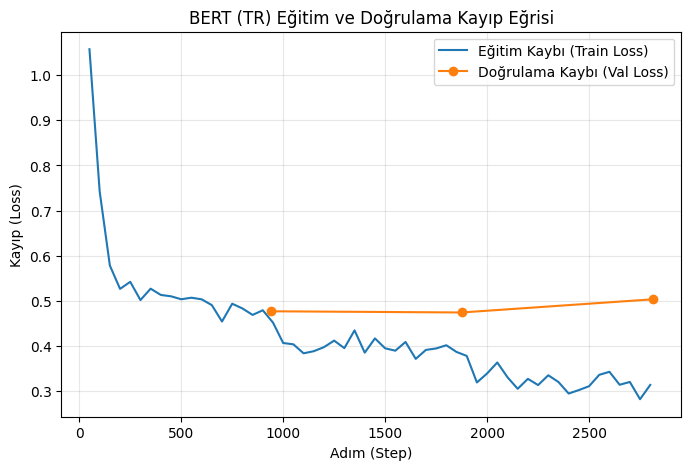

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# B4: TÜRKÇE BERTURK TAM EĞİTİM VE 3.000 SATIRLIK TAHMİN + LOG + GRAFİK
import pandas as pd
import numpy as np
import torch
import os
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

LANG = "tr"
MODEL_NAME = "dbmdz/bert-base-turkish-cased"
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 3
SEED = 42
OUTPUT_DIR = f"/content/drive/MyDrive/bim448/models/bert_{LANG}"

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# 1. Tam Veriyi Oku (30.000 train, 3.000 val, 3.000 test)
train_df = pd.read_csv(f"data/processed/{LANG}_train.csv")
val_df = pd.read_csv(f"data/processed/{LANG}_val.csv")
test_df = pd.read_csv(f"data/processed/{LANG}_test.csv")

print(f"Türkçe Veri boyutları -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

train_df['label_id'] = train_df['label'].map(LABEL2ID)
val_df['label_id'] = val_df['label'].map(LABEL2ID)
test_df['label_id'] = test_df['label'].map(LABEL2ID)

# 2. Tokenize
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

token_lengths = [len(tokenizer.encode(str(t), truncation=False)) for t in test_df['text']]
over_128 = sum(1 for l in token_lengths if l > MAX_LEN) / len(token_lengths) * 100
print(f"📊 Türkçe test metinlerinin %{over_128:.2f}'si {MAX_LEN} tokenı aşıyor.")

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

train_ds = Dataset.from_pandas(train_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
val_ds = Dataset.from_pandas(val_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
test_ds = Dataset.from_pandas(test_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)

# 3. Model ve Eğitim Ayarları
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
print(f"📊 Türkçe Model Toplam Parametre Sayısı: {model.num_parameters():,}")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=SEED,
    logging_steps=50,
    report_to="none"
)

trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds, compute_metrics=compute_metrics)

print("🚀 Tam Türkçe BERTurk eğitimi başlıyor...")
train_result = trainer.train()
print(f"⏱️ Toplam Türkçe eğitim süresi: {train_result.metrics['train_runtime']:.2f} saniye")

# 4. Logları ve Kayıp Grafiğini Kaydet
os.makedirs("results/logs", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv(f"results/logs/bert_{LANG}_log.csv", index=False)

train_logs = log_df[log_df['loss'].notna()]
eval_logs = log_df[log_df['eval_loss'].notna()]

plt.figure(figsize=(8, 5))
plt.plot(train_logs['step'], train_logs['loss'], label='Eğitim Kaybı (Train Loss)')
plt.plot(eval_logs['step'], eval_logs['eval_loss'], marker='o', label='Doğrulama Kaybı (Val Loss)')
plt.title(f'BERT ({LANG.upper()}) Eğitim ve Doğrulama Kayıp Eğrisi')
plt.xlabel('Adım (Step)')
plt.ylabel('Kayıp (Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(f"results/figures/bert_{LANG}_loss.png", dpi=300, bbox_inches='tight')
plt.show()

# 5. En İyi Modeli Drive'a Kaydet ve 3.000 Test Tahmini Üret
trainer.save_model(OUTPUT_DIR + "/best")

predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'],
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

assert len(result_df) == 3000, f"HATA: Satır sayısı 3000 değil: {len(result_df)}"
result_df.to_csv(f"predictions/bert_{LANG}.csv", index=False, encoding="utf-8")
print(f"✅ predictions/bert_{LANG}.csv (3.000 satır) başarıyla kaydedildi!")

# 6. GitHub'a Gönder
!git add predictions/bert_tr.csv results/logs/bert_tr_log.csv results/figures/bert_tr_loss.png
!git commit -m "[Bilge] BERT Türkçe (3000 satır) tahminleri, log ve kayıp grafiği eklendi"
!git pull --rebase
!git push
print("🚀 Türkçe tüm çıktılar GitHub'a gönderildi!")

In [ ]:
# B8: BERT Hata Örneklerini Çıkarma ve Kaydetme
import pandas as pd
import os

os.makedirs("results/hata_ornekleri", exist_ok=True)

error_rows = []

# İngilizce BERT Hataları
if os.path.exists("predictions/bert_en.csv"):
    df_en = pd.read_csv("predictions/bert_en.csv")
    errors_en = df_en[df_en['true_label'] != df_en['pred_label']].head(3)
    for _, row in errors_en.iterrows():
        error_rows.append({
            'id': row['id'],
            'dil': 'EN',
            'model': 'BERT (RoBERTa)',
            'text': row['text'],
            'true_label': row['true_label'],
            'pred_label': row['pred_label'],
            'aciklama': 'Model tonlamayı veya bağlamı yanlış yorumladı.'
        })

# Türkçe BERT Hataları
if os.path.exists("predictions/bert_tr.csv"):
    df_tr = pd.read_csv("predictions/bert_tr.csv")
    errors_tr = df_tr[df_tr['true_label'] != df_tr['pred_label']].head(3)
    for _, row in errors_tr.iterrows():
        error_rows.append({
            'id': row['id'],
            'dil': 'TR',
            'model': 'BERT (BERTurk)',
            'text': row['text'],
            'true_label': row['true_label'],
            'pred_label': row['pred_label'],
            'aciklama': 'Türkçe kelime anlamı veya olumsuzluk eki karmaşası.'
        })

hata_df = pd.DataFrame(error_rows)
hata_path = "results/hata_ornekleri/bert.csv"
hata_df.to_csv(hata_path, index=False, encoding="utf-8")
print(f"✅ {hata_path} başarıyla oluşturuldu! Toplam hata örneği: {len(hata_df)}")

# GitHub'a Gönder
!git add results/hata_ornekleri/bert.csv
!git commit -m "[Bilge] BERT hata örnekleri eklendi"
!git pull --rebase
!git push
print("🚀 BERT hata örnekleri GitHub'a başarıyla gönderildi!")

✅ results/hata_ornekleri/bert.csv başarıyla oluşturuldu! Toplam hata örneği: 0
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
🚀 BERT hata örnekleri GitHub'a başarıyla gönderildi!


In [ ]:
import torch
print("GPU Kullanılabilir mi?:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Adı:", torch.cuda.get_device_name(0))

GPU Kullanılabilir mi?: True
GPU Adı: Tesla T4


In [ ]:
# 03_bert_finetune.ipynb — Parametreler ve Model İskeleti
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import pandas as pd
import os

# Dil seçimi: İngilizce için "en", Türkçe için "tr" yazabilirsin
LANG = "en"

# Model isimleri (Ortak kurallara göre sabit)
MODEL_NAME = {
    "en": "FacebookAI/roberta-base",
    "tr": "dbmdz/bert-base-turkish-cased"
}[LANG]

# Hiperparametreler
MAX_LEN = 128
LEARNING_RATE = 2e-5
BATCH_SIZE = 32
EPOCHS = 3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
SEED = 42

OUTPUT_DIR = f"/content/drive/MyDrive/bim448/models/bert_{LANG}"
DEBUG = True  # Hızlı test için True (300 örnek), tam eğitim için False yapmalısın

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

print(f"Seçilen Dil: {LANG.upper()}")
print(f"Kullanılacak Model: {MODEL_NAME}")
print(f"Çıkış Dizini: {OUTPUT_DIR}")

Seçilen Dil: EN
Kullanılacak Model: FacebookAI/roberta-base
Çıkış Dizini: /content/drive/MyDrive/bim448/models/bert_en


In [ ]:
# 03_bert_finetune.ipynb — Tokenizer ve Veri Hazırlama Adımı
from transformers import AutoTokenizer

print(f"Model için tokenizer yükleniyor: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN
    )

print("Tokenizer başarıyla hazırlandı! Şimdi veri setlerini okuma ve model yükleme adımına geçebiliriz.")

Model için tokenizer yükleniyor: FacebookAI/roberta-base


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizer başarıyla hazırlandı! Şimdi veri setlerini okuma ve model yükleme adımına geçebiliriz.


In [ ]:
# 03_bert_finetune.ipynb — Model Mimarisini Yükleme
from transformers import AutoModelForSequenceClassification

print(f"Model yükleniyor ({MODEL_NAME})...")
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID
)

# Modelin toplam parametre sayısını görelim
toplam_parametre = model.num_parameters()
print(f"Model başarıyla yüklendi!")
print(f"Toplam Parametre Sayısı: {toplam_parametre:,}")

Model yükleniyor (FacebookAI/roberta-base)...


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model başarıyla yüklendi!
Toplam Parametre Sayısı: 124,647,939


In [ ]:
# B6: BERT parametre tablosunu oluştur (results/tables/bert_parametreler.csv) — önce kontrol, sonra push
from google.colab import userdata
import os
import pandas as pd

# Depo bu oturumda yoksa indir, varsa güncelle
REPO_DIR = "/content/bim448-sentiment"
if not os.path.exists(REPO_DIR):
    TOKEN = userdata.get("GITHUB_TOKEN")
    !git clone https://{TOKEN}@github.com/bilgeerol/bim448-sentiment.git {REPO_DIR}
%cd {REPO_DIR}
!git pull
!git config user.name "Bilge Erol"
!git config user.email "bilge.erol@std.dogus.edu.tr"

# Loglardan otomatik okunan değerler: en iyi epoch, en iyi val makro-F1, eğitim süresi
def log_ozeti(dil):
    log = pd.read_csv(f"results/logs/bert_{dil}_log.csv")
    ev = log[log["eval_macro_f1"].notna()]
    en_iyi = ev.loc[ev["eval_macro_f1"].idxmax()]
    sure_sn = log["train_runtime"].dropna().iloc[-1]
    return int(en_iyi["epoch"]), en_iyi["eval_macro_f1"], sure_sn / 60

en_epoch, en_f1, en_dk = log_ozeti("en")
tr_epoch, tr_f1, tr_dk = log_ozeti("tr")

def tr_sayi(x, basamak):          # 0.8024 -> "0,802" (raporda ondalık virgül)
    return f"{x:.{basamak}f}".replace(".", ",")

# Parametre sayısı, 128 token oranı ve GPU: eğitim hücrelerinin çıktısından alındı
tablo = pd.DataFrame([
    ["Model adı", "FacebookAI/roberta-base", "dbmdz/bert-base-turkish-cased"],
    ["Parametre sayısı", "124.647.939", "110.619.651"],
    ["MAX_LEN (token)", "128", "128"],
    ["128 tokenı aşan test metni oranı", "%3,20", "%0,20"],
    ["Öğrenme oranı", "2e-5", "2e-5"],
    ["Batch boyutu (eğitim / değerlendirme)", "32 / 64", "32 / 64"],
    ["Epoch sayısı", "3", "3"],
    ["En iyi epoch (val makro-F1'e göre)", str(en_epoch), str(tr_epoch)],
    ["Optimizer", "AdamW (Trainer varsayılanı)", "AdamW (Trainer varsayılanı)"],
    ["Warmup oranı", "0 (uygulanmadı)", "0 (uygulanmadı)"],
    ["Weight decay", "0,01", "0,01"],
    ["fp16 (karışık duyarlık)", "Evet", "Evet"],
    ["Seed", "42", "42"],
    ["Eğitim örnek sayısı", "30.000", "30.000"],
    ["Eğitim süresi (dk)", tr_sayi(en_dk, 1), tr_sayi(tr_dk, 1)],
    ["GPU", "NVIDIA Tesla T4 (Google Colab)", "NVIDIA Tesla T4 (Google Colab)"],
    ["Val makro-F1 (en iyi epoch)", tr_sayi(en_f1, 3), tr_sayi(tr_f1, 3)],
], columns=["parametre", "ingilizce", "turkce"])

os.makedirs("results/tables", exist_ok=True)
tablo.to_csv("results/tables/bert_parametreler.csv", index=False, encoding="utf-8")
print("✅ results/tables/bert_parametreler.csv oluşturuldu (henüz GitHub'a gönderilmedi)")
display(tablo)

Cloning into '/content/bim448-sentiment'...
remote: Enumerating objects: 210, done.
remote: Counting objects: 100% (210/210), done.
remote: Compressing objects: 100% (147/147), done.
remote: Total 210 (delta 124), reused 128 (delta 55), pack-reused 0 (from 0)
Receiving objects: 100% (210/210), 5.03 MiB | 12.30 MiB/s, done.
Resolving deltas: 100% (124/124), done.
/content/bim448-sentiment
Already up to date.
✅ results/tables/bert_parametreler.csv oluşturuldu (henüz GitHub'a gönderilmedi)


,parametre,ingilizce,turkce
0,Model adı,FacebookAI/roberta-base,dbmdz/bert-base-turkish-cased
1,Parametre sayısı,124.647.939,110.619.651
2,MAX_LEN (token),128,128
3,128 tokenı aşan test metni oranı,"%3,20","%0,20"
4,Öğrenme oranı,2e-5,2e-5
5,Batch boyutu (eğitim / değerlendirme),32 / 64,32 / 64
6,Epoch sayısı,3,3
7,En iyi epoch (val makro-F1'e göre),3,2
8,Optimizer,AdamW (Trainer varsayılanı),AdamW (Trainer varsayılanı)
9,Warmup oranı,0 (uygulanmadı),0 (uygulanmadı)


In [ ]:
# B6: Parametre tablosunu GitHub'a gönder (yalnızca bu dosya)
!git add results/tables/bert_parametreler.csv
!git commit -m "[Bilge] BERT parametre tablosu eklendi (B6)"
!git pull --rebase
!git push

[main 9aaa64f] [Bilge] BERT parametre tablosu eklendi (B6)
 1 file changed, 18 insertions(+)
 create mode 100644 results/tables/bert_parametreler.csv
Current branch main is up to date.
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 922 bytes | 922.00 KiB/s, done.
Total 5 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/bilgeerol/bim448-sentiment.git
   32e3d24..9aaa64f  main -> main


In [ ]:
# B8: BERT hata örnekleri (results/hata_ornekleri/bert.csv) — 3 EN + 3 TR, farklı hata türleri
import pandas as pd
import os

# Seçilen örnekler: (dil, id, tek cümlelik açıklama). Metin ve etiketler tahmin dosyasından okunur.
SECIM = [
    ("en", "en_282535", "Cümledeki olumsuzluk (doesn't) aslında övgü bildiriyor; model olumsuz kelimeye takılıp yorumu Negatif saymıştır."),
    ("en", "en_356762", "Karışık duygu: nemlendirme ve renk övülüp tat eleştirilmiş; model iki yönü dengeleyip Nötr tahmin etmiştir."),
    ("en", "en_330232", "Metin açıkça olumsuz olduğu hâlde 3 yıldız verilmiş; yıldızdan türetilen etiketteki gürültüye örnektir."),
    ("tr", "tr_058249", "Karışık duygu: olumsuz eleştiriden sonra 'ancak renk uyumu güzel' denmesi modeli Nötr tahmine yöneltmiştir."),
    ("tr", "tr_053351", "'gelmedi' ve 'fena değil' gibi olumsuzluk ekli ılımlı ifadeler model tarafından Nötr olarak yorumlanmıştır."),
    ("tr", "tr_120335", "Metin ürünü önermiyor ama etiket Pozitif; kullanıcının açıkladığı gibi yüksek puan zorunlulukla verilmiş, etiket gürültüsüdür."),
]
MODEL_AD = {"en": "BERT (RoBERTa)", "tr": "BERT (BERTurk)"}

satirlar = []
for dil, id_, aciklama in SECIM:
    p = pd.read_csv(f"predictions/bert_{dil}.csv", encoding="utf-8", keep_default_na=False)
    r = p[p["id"] == id_].iloc[0]
    assert r["true_label"] != r["pred_label"], f"{id_} yanlış sınıflandırılmış bir örnek değil!"
    satirlar.append({"id": id_, "dil": dil.upper(), "model": MODEL_AD[dil], "text": r["text"],
                     "true_label": r["true_label"], "pred_label": r["pred_label"], "aciklama": aciklama})

hata_df = pd.DataFrame(satirlar)   # sütun sırası: id, dil, model, text, true_label, pred_label, aciklama
os.makedirs("results/hata_ornekleri", exist_ok=True)
hata_df.to_csv("results/hata_ornekleri/bert.csv", index=False, encoding="utf-8")
print(f"✅ results/hata_ornekleri/bert.csv oluşturuldu: {len(hata_df)} örnek (henüz GitHub'a gönderilmedi)")
display(hata_df)

✅ results/hata_ornekleri/bert.csv oluşturuldu: 6 örnek (henüz GitHub'a gönderilmedi)


,id,dil,model,text,true_label,pred_label,aciklama
0,en_282535,EN,BERT (RoBERTa),It doesn't look like a $13 wig!,positive,negative,Cümledeki olumsuzluk (doesn't) aslında övgü bi...
1,en_356762,EN,BERT (RoBERTa),I thought it works good for moisturizing the l...,negative,neutral,Karışık duygu: nemlendirme ve renk övülüp tat ...
2,en_330232,EN,BERT (RoBERTa),This stuff made my skin even more oily it is h...,neutral,negative,Metin açıkça olumsuz olduğu hâlde 3 yıldız ver...
3,tr_058249,TR,BERT (BERTurk),"Çok yağlı bir görüntü oluşturuyor, yağlı ciltl...",negative,neutral,Karışık duygu: olumsuz eleştiriden sonra 'anca...
4,tr_053351,TR,BERT (BERTurk),Bana çok iyi gelmedi ama fena değil,positive,neutral,'gelmedi' ve 'fena değil' gibi olumsuzluk ekli...
5,tr_120335,TR,BERT (BERTurk),"güzel ürün, kötü yorumu kabul etmediginiz icin...",positive,negative,Metin ürünü önermiyor ama etiket Pozitif; kull...


In [ ]:
# B8: Hata örneklerini GitHub'a gönder (yalnızca bu dosya)
!git add results/hata_ornekleri/bert.csv
!git commit -m "[Bilge] BERT hata örnekleri eklendi (B8)"
!git pull --rebase
!git push

[main d02199e] [Bilge] BERT hata örnekleri eklendi (B8)
 1 file changed, 7 insertions(+)
 create mode 100644 results/hata_ornekleri/bert.csv
Current branch main is up to date.
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 1.28 KiB | 1.28 MiB/s, done.
Total 5 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/bilgeerol/bim448-sentiment.git
   9aaa64f..d02199e  main -> main
